# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

**Reference:** John Sukup, *scikit-learn Cookbook*, Third Edition (2025).

This notebook follows the main topics of Chapter 4. The demonstrations are independently written and pair each code example with a short explanation of its output.

**Source:** John Sukup, *scikit-learn Cookbook*, Third Edition (Packt, 2025). The sections below follow the topics and selected examples presented in the book. Explanations and interpretations are summarized in original English.

## 1. Introduction to distance metrics

Nearest-neighbor methods compare samples by measuring how far apart they are. The selected metric determines which observations count as similar, making feature scale and metric choice important.

In [10]:
import numpy as np
from scipy.spatial.distance import euclidean, cityblock, cosine
u=np.array([1.,2.,3.]); v=np.array([3.,2.,1.])
print('Euclidean:',round(euclidean(u,v),3))
print('Manhattan:',round(cityblock(u,v),3))
print('Cosine distance:',round(cosine(u,v),3))

Euclidean: 2.828
Manhattan: 4.0
Cosine distance: 0.286


**Interpretation**

The three metrics produce different numbers for the same pair of vectors. Euclidean distance measures straight-line separation, Manhattan sums coordinate differences, and cosine distance reflects direction.

## 2. Understanding KNNs

K-nearest neighbors predicts a label from nearby training examples. It does not construct a conventional parametric formula; predictions depend directly on the distances to stored samples.

In [11]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
wine=load_wine()
X_train,X_test,y_train,y_test=train_test_split(wine.data,wine.target,test_size=.3,random_state=42,stratify=wine.target)
knn=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train,y_train)
print('First 10 predictions:',knn.predict(X_test[:10]))
print('Actual labels:',y_test[:10])
print('Test accuracy:',round(knn.score(X_test,y_test),3))

First 10 predictions: [0 1 0 0 0 0 2 1 1 2]
Actual labels: [0 1 0 0 0 0 2 1 1 2]
Test accuracy: 0.944


**Interpretation**

Comparing predicted and actual labels shows which test samples were classified correctly. Test accuracy reflects unseen observations and is more meaningful than merely reporting training accuracy.

## 3. Distance metrics overview

The `metric` parameter can change the definition of the neighborhood. L1 (Manhattan) and L2 (Euclidean) distances can lead to different nearest samples, especially when features are correlated.

In [12]:
for metric in ['euclidean','manhattan']:
    estimator=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5,metric=metric))
    estimator.fit(X_train,y_train)
    print(metric, 'test accuracy:',round(estimator.score(X_test,y_test),3))

euclidean test accuracy: 0.944
manhattan test accuracy: 0.981


**Interpretation**

Even after standardization, different metrics may produce different classification outcomes. Metric selection should be evaluated using validation data rather than chosen solely by habit.

## 4. Hyperparameter tuning in KNN

The value of `n_neighbors` controls how local a prediction is. Smaller values can follow noise closely, while larger values produce smoother decision boundaries.

In [13]:
from sklearn.model_selection import GridSearchCV
search=GridSearchCV(make_pipeline(StandardScaler(),KNeighborsClassifier()),
                    {'kneighborsclassifier__n_neighbors':[1,3,5,7,9],
                     'kneighborsclassifier__weights':['uniform','distance']},cv=5)
search.fit(X_train,y_train)
print('Best parameters:',search.best_params_)
print('Validation accuracy:',round(search.best_score_,3))
print('Holdout accuracy:',round(search.score(X_test,y_test),3))

Best parameters: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'}
Validation accuracy: 0.959
Holdout accuracy: 0.944


**Interpretation**

Grid search selects the neighbor count and weighting method with the best average validation result. The separate holdout score checks how this selection behaves outside the tuning folds.

## 5. Evaluating KNN performance

A confusion matrix indicates which categories are confused, while a classification report summarizes precision, recall and F1-score. These metrics provide more detail than accuracy alone.

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.86      0.92        21
     class_2       0.83      1.00      0.91        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54



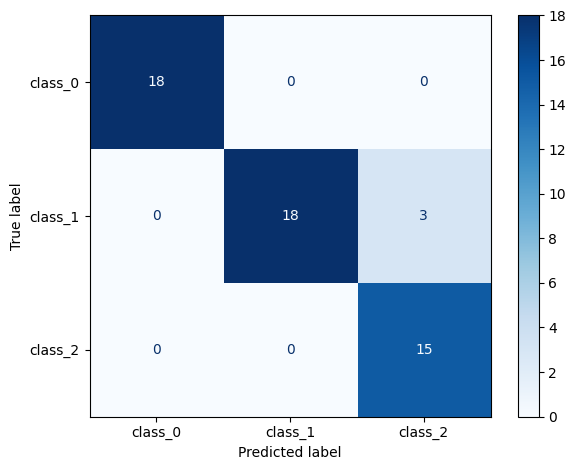

In [14]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
pred=search.predict(X_test)
print(classification_report(y_test,pred,target_names=wine.target_names))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=wine.target_names,cmap='Blues')
plt.tight_layout();plt.show()

**Interpretation**

Correct predictions appear along the matrix diagonal; off-diagonal entries show classification errors. Precision and recall reveal whether mistakes are concentrated in particular wine classes.

## 6. Practical exercises with KNN models

Neighbor models are sensitive to feature scaling because each coordinate contributes to distance calculations. A direct comparison with and without scaling demonstrates this issue.

In [15]:
raw_knn=KNeighborsClassifier(n_neighbors=5).fit(X_train,y_train)
scaled_knn=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)).fit(X_train,y_train)
print('Without scaling:',round(raw_knn.score(X_test,y_test),3))
print('With scaling:',round(scaled_knn.score(X_test,y_test),3))

Without scaling: 0.722
With scaling: 0.944


**Interpretation**

Unscaled distances are often dominated by features with larger numeric ranges. Standardization can improve balance among measurements, although the size of the improvement depends on the dataset.

## 7. Inspecting neighboring observations

It is possible to inspect which training cases a test sample is closest to. This can help explain a prediction, while also showing that a result can depend on a small local group.

In [16]:
distances, indices=scaled_knn.named_steps['kneighborsclassifier'].kneighbors(
    scaled_knn.named_steps['standardscaler'].transform(X_test[:1]))
print('Neighbor distances:',distances.round(3))
print('Neighbor labels:',y_train[indices[0]])
print('Predicted label:',scaled_knn.predict(X_test[:1]))

Neighbor distances: [[2.029 2.055 2.214 2.559 2.625]]
Neighbor labels: [0 0 0 0 0]
Predicted label: [0]


**Interpretation**

The selected neighbor labels show the local evidence behind the classifier’s decision. Short distances indicate nearby training cases under the chosen standardized feature representation.

## Book recipe: KNN classifier on the Iris dataset

The book uses Iris examples for nearest-neighbor classification and evaluation. The model predicts a flower class by voting among nearby training examples.

In [17]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
iris_book = load_iris()
X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(iris_book.data, iris_book.target, test_size=0.2, random_state=42, stratify=iris_book.target)
knn_book = KNeighborsClassifier(n_neighbors=5)
knn_book.fit(X_train_k, y_train_k)
y_pred_k = knn_book.predict(X_test_k)
print('Accuracy:', round(accuracy_score(y_test_k,y_pred_k),4))
print('Confusion matrix:\n', confusion_matrix(y_test_k,y_pred_k))
print(classification_report(y_test_k,y_pred_k, target_names=iris_book.target_names))

Accuracy: 1.0
Confusion matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



**Interpretation**

The confusion matrix places correct predictions on the diagonal and errors off the diagonal. The report separates precision, recall, and F1-score by flower class, which gives a fuller picture than accuracy alone.

## Book recipe: KNN hyperparameter tuning with GridSearchCV

The book also uses grid search to compare settings rather than selecting the neighborhood size by guesswork.

In [18]:
from sklearn.model_selection import GridSearchCV
knn_search_book = GridSearchCV(KNeighborsClassifier(), {'n_neighbors':[3,5,7,9], 'weights':['uniform','distance'], 'metric':['euclidean','manhattan']}, cv=5)
knn_search_book.fit(X_train_k,y_train_k)
print('Best parameters:',knn_search_book.best_params_)
print('Cross-validation score:',round(knn_search_book.best_score_,4))
print('Test score:',round(knn_search_book.score(X_test_k,y_test_k),4))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'}
Cross-validation score: 0.975
Test score: 1.0


**Interpretation**

Grid search selects the combination with the highest mean cross-validation score among the tested settings. The separate test score is useful because the cross-validation result was involved in choosing the model.